# LAB 5 : To implement a Generative Learning Algorithm

Training Dataset

In [10]:
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=4, suppress=True)

X0 = np.array([[2,3],[3,2],[4,4],[2,4],[4,3],
               [3,4],[1,3],[3,1],[4,2],[2,2]], dtype=float)

X1 = np.array([[7,8],[8,7],[9,9],[7,9],[9,8],
               [8,9],[6,8],[8,6],[9,7],[7,7]], dtype=float)

X = np.vstack([X0, X1])
y = np.array([0]*len(X0) + [1]*len(X1))

x_test = np.array([5,7], dtype=float)

m,n = X.shape
print("m = ",m, ", n = ",n)
print("Class 0 Samples: ",(y==0).sum()," , Class 1 Samples: ",(y==1).sum())


m =  20 , n =  2
Class 0 Samples:  10  , Class 1 Samples:  10


Task 1: Maximum Likelihood Parameter Estimation

In [11]:
# 1) Class prior

phi = np.sum(y==1)/m
P_y1 = phi
P_y0 = 1-phi

print("Class Prior phi :", phi)
print("P(y=1) :", P_y1)
print("P(y=0) :", P_y0)

Class Prior phi : 0.5
P(y=1) : 0.5
P(y=0) : 0.5


In [12]:
# 2) Class Means

mu = {}
for k in [0,1]:
    indicator =  (y==k)
    sum_x = X[indicator].sum(axis=0)
    count = indicator.sum()
    mu[k] = sum_x/count
    print(f"Sum of x {sum_x} , count = {count}")
    print(f"mu_{k} = {mu[k]}")

mu0, mu1 = mu[0], mu[1]

Sum of x [28. 28.] , count = 10
mu_0 = [2.8 2.8]
Sum of x [78. 78.] , count = 10
mu_1 = [7.8 7.8]


In [13]:
# 3) Shared Covariance Matrix

Sigma = np.zeros((n,n))
for i in range(m):
    d = (X[i] - mu[y[i]]).reshape(n,1)
    Sigma += d @ d.T

Sigma /= m

print("Sum of outer products (before dividing by m):\n", Sigma * m)
print("\nSigma =\n", Sigma)
print("|Sigma| =", np.linalg.det(Sigma))
print("Sigma^-1 =\n", np.linalg.inv(Sigma))


Sum of outer products (before dividing by m):
 [[19.2 -0.8]
 [-0.8 19.2]]

Sigma =
 [[ 0.96 -0.04]
 [-0.04  0.96]]
|Sigma| = 0.9200000000000005
Sigma^-1 =
 [[1.0435 0.0435]
 [0.0435 1.0435]]


Task 2: Probability Density Formulation

In [14]:
Sigma_inv = np.linalg.inv(Sigma)
Sigma_det = np.linalg.det(Sigma)
norm_const = 1.0 / ((2 * np.pi) ** (n / 2) * np.sqrt(Sigma_det))

def gaussian_pdf(x, mean, cov_inv=Sigma_inv, const=norm_const):
    d = (x - mean).reshape(-1, 1)
    exponent = -0.5 * (d.T @ cov_inv @ d).item()
    return const * np.exp(exponent)

print("Normalisation constant =", norm_const)

print("\nP(x | y=0) = %.4f " % norm_const)
print("  mu0 =", mu0)
print("\nP(x | y=1) = %.4f " % norm_const)
print("  mu1 =", mu1)
print("\nSigma =\n", Sigma)
print("Sigma^-1 =\n", Sigma_inv)


print("\nPeak density P(mu0 | y=0) =", gaussian_pdf(mu0, mu0))
print("Peak density P(mu1 | y=1) =", gaussian_pdf(mu1, mu1))

Normalisation constant = 0.16593049851546815

P(x | y=0) = 0.1659 
  mu0 = [2.8 2.8]

P(x | y=1) = 0.1659 
  mu1 = [7.8 7.8]

Sigma =
 [[ 0.96 -0.04]
 [-0.04  0.96]]
Sigma^-1 =
 [[1.0435 0.0435]
 [0.0435 1.0435]]

Peak density P(mu0 | y=0) = 0.16593049851546815
Peak density P(mu1 | y=1) = 0.16593049851546815


Task 3: Inference and Posterior Probabilities


In [15]:
# 4. Likelihoods
d0 = x_test - mu0
d1 = x_test - mu1

lik0 = gaussian_pdf(x_test, mu0)
lik1 = gaussian_pdf(x_test, mu1)

print("x_test =", x_test)
print(f"x_test - mu0 = {d0}")
print(f"x_test - mu1 = {d1}")
print("\n--- 4. Likelihoods ---")
print(f"P(x_test | y=0) = {lik0:.6e}")
print(f"P(x_test | y=1) = {lik1:.6e}")


x_test = [5. 7.]
x_test - mu0 = [2.2 4.2]
x_test - mu1 = [-2.8 -0.8]

--- 4. Likelihoods ---
P(x_test | y=0) = 8.948399e-07
P(x_test | y=1) = 1.803682e-03


In [16]:
# 5. Posteriors
joint0 = lik0 * P_y0
joint1 = lik1 * P_y1
evidence = joint0 + joint1

post0 = joint0 / evidence
post1 = joint1 / evidence

print(f"P(x_test | y=0) P(y=0) = {joint0:.6e}")
print(f"P(x_test | y=1) P(y=1) = {joint1:.6e}")
print(f"Evidence P(x_test)     = {evidence:.6e}")
print(f"\nP(y=0 | x_test) = {post0:.6f}")
print(f"P(y=1 | x_test) = {post1:.6f}")
print("Sum of posteriors =", post0 + post1)

P(x_test | y=0) P(y=0) = 4.474199e-07
P(x_test | y=1) P(y=1) = 9.018408e-04
Evidence P(x_test)     = 9.022882e-04

P(y=0 | x_test) = 0.000496
P(y=1 | x_test) = 0.999504
Sum of posteriors = 1.0


In [17]:
# 6. Decision
pred = int(post1 > post0)
print(f"Higher posterior -> x_test is assigned to Class {pred}")

Higher posterior -> x_test is assigned to Class 1


Task 4: Visualization

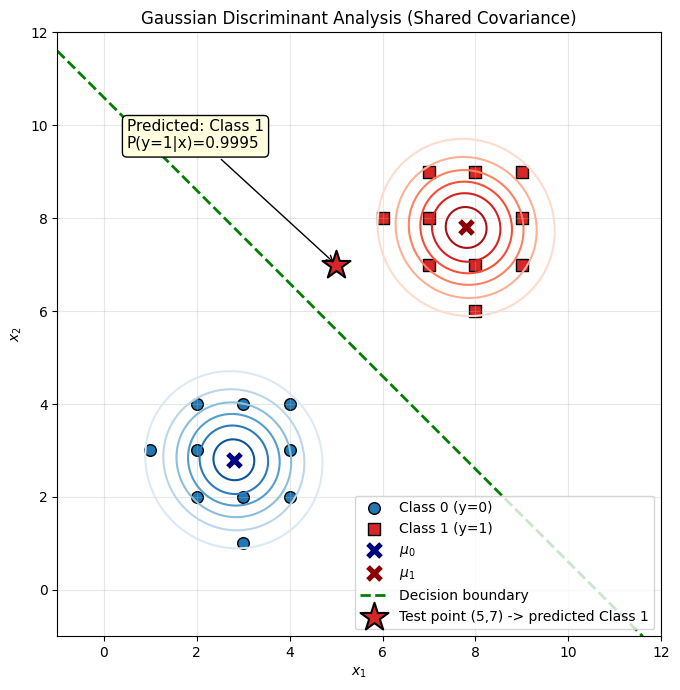

In [18]:
xs = np.linspace(-1, 12, 300)
ys = np.linspace(-1, 12, 300)
XX, YY = np.meshgrid(xs, ys)
grid = np.stack([XX.ravel(), YY.ravel()], axis=1)

def pdf_grid(mean):
    d = grid - mean
    expo = -0.5 * np.einsum('ij,jk,ik->i', d, Sigma_inv, d)
    return (norm_const * np.exp(expo)).reshape(XX.shape)

Z0 = pdf_grid(mu0)
Z1 = pdf_grid(mu1)

fig, ax = plt.subplots(figsize=(8, 7))

ax.scatter(X0[:, 0], X0[:, 1], c="tab:blue", marker="o", s=70,
           edgecolors="k", label="Class 0 (y=0)")
ax.scatter(X1[:, 0], X1[:, 1], c="tab:red", marker="s", s=70,
           edgecolors="k", label="Class 1 (y=1)")

ax.scatter(*mu0, c="navy", marker="X", s=180, edgecolors="w", label=r"$\mu_0$")
ax.scatter(*mu1, c="darkred", marker="X", s=180, edgecolors="w", label=r"$\mu_1$")

ax.contour(XX, YY, Z0, levels=6, cmap="Blues")
ax.contour(XX, YY, Z1, levels=6, cmap="Reds")

log_ratio = (np.log(Z1 + 1e-300) + np.log(P_y1)) - (np.log(Z0 + 1e-300) + np.log(P_y0))
ax.contour(XX, YY, log_ratio, levels=[0], colors="green", linestyles="--", linewidths=2)
ax.plot([], [], "g--", linewidth=2, label="Decision boundary")

pred_color = "tab:red" if pred == 1 else "tab:blue"
ax.scatter(*x_test, c=pred_color, marker="*", s=450, edgecolors="k", linewidths=1.5,
           label=f"Test point (5,7) -> predicted Class {pred}")
ax.annotate(f"Predicted: Class {pred}\nP(y={pred}|x)={max(post0, post1):.4f}",
            xy=x_test, xytext=(x_test[0] - 4.5, x_test[1] + 2.5),
            arrowprops=dict(arrowstyle="->"), fontsize=11,
            bbox=dict(boxstyle="round", fc="lightyellow"))

ax.set_xlabel("$x_1$")
ax.set_ylabel("$x_2$")
ax.set_title("Gaussian Discriminant Analysis (Shared Covariance)")
ax.legend(loc="lower right")
ax.grid(alpha=0.3)
ax.set_aspect("equal")
plt.tight_layout()
plt.show()